# Trajectories and behavior: segment shuttle traversals

**Estimated time**: 20-25 minutes

**Prerequisites**: [01: getting started](01_getting_started.ipynb).

Represent a bent track, identify movement epochs and source-to-target runs,
and compare their progress using graph distance. The simulated recording has
pauses and an intentional tracking gap. Every summary distinguishes observed
movement from unknown behavior during that gap. No download is required.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import Point

from neurospatial import Environment
from neurospatial.behavior import (
    compute_step_lengths,
    detect_region_crossings,
    detect_runs_between_regions,
    path_progress,
    segment_by_velocity,
)

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(11, 5))

## 1. Define the track before projecting tracking data

The ordered waypoints define a 100 cm L-shaped centerline with 2 cm bins.
This topology is experimental knowledge; a position cloud alone cannot define
the track. The graph retains its embedding in 2D while providing a 1D distance
coordinate. `edge_spacing=0` avoids artificial gaps in that coordinate.

Projection places observations on a centerline. It can conceal off-track
tracking errors or assign the wrong branch near a junction. Inspect projection
residuals and verify the graph against your apparatus before using its bins.

Recorded samples: 2,923; track bins: 50
95th percentile projection residual: 0.04 cm


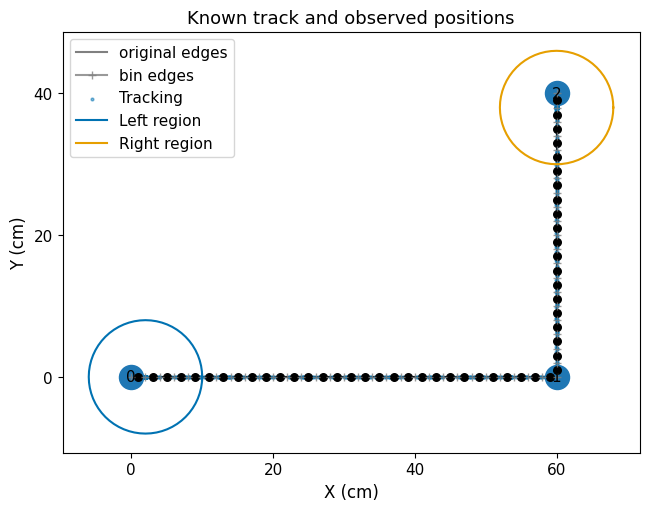

In [2]:
track = Environment.linear_track(
    node_positions=[(0.0, 0.0), (60.0, 0.0), (60.0, 40.0)],
    bin_size=2.0,
    edge_spacing=0.0,
    units="cm",
    frame="track",
    name="Bent shuttle track",
)
track.regions.add("left", polygon=Point(2.0, 0.0).buffer(8.0))
track.regions.add("right", polygon=Point(60.0, 38.0).buffer(8.0))

# Repeated traversals with independent, seeded variation in duration and pauses.
rng = np.random.default_rng(303)
knot_times, knot_distances = [0.0, 1.5], [2.0, 2.0]
for _ in range(4):
    for destination, duration in [
        (98.0, rng.uniform(4.0, 7.0)),
        (98.0, rng.uniform(1.2, 2.0)),
        (2.0, rng.uniform(4.0, 7.0)),
        (2.0, rng.uniform(1.2, 2.0)),
    ]:
        knot_times.append(knot_times[-1] + duration)
        knot_distances.append(destination)

full_times = np.arange(0.0, knot_times[-1], 0.02)
distance = np.interp(full_times, knot_times, knot_distances)
full_positions = track.linear_to_nd(distance)
full_positions += rng.normal(0.0, 0.02, size=full_positions.shape)

# Remove one second from the middle of the second outward traversal.
gap_center = (knot_times[5] + knot_times[6]) / 2
keep = np.abs(full_times - gap_center) > 0.5
times, positions = full_times[keep], full_positions[keep]
linear_position = track.to_linear(positions)
projected = track.linear_to_nd(linear_position)
residual = np.linalg.norm(positions - projected, axis=1)
position_bins = track.bin_at(positions)
assert np.all(position_bins >= 0) and np.all(np.diff(times) > 0)
print(f"Recorded samples: {len(times):,}; track bins: {track.n_bins}")
print(f"95th percentile projection residual: {np.percentile(residual, 95):.2f} cm")

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
track.plot(ax=ax)
ax.scatter(*positions[::5].T, s=4, alpha=0.5, label="Tracking")
for name in ["left", "right"]:
    boundary_x, boundary_y = track.regions[name].data.exterior.xy
    ax.plot(boundary_x, boundary_y, label=f"{name.capitalize()} region")
ax.set(xlabel="X (cm)", ylabel="Y (cm)", title="Known track and observed positions")
ax.set_xticks([0, 20, 40, 60])
ax.set_yticks([0, 20, 40])
ax.tick_params(bottom=True, left=True, labelbottom=True, labelleft=True)
handles, labels = ax.get_legend_handles_labels()
legend_entries = dict(zip(labels, handles))
ax.legend(legend_entries.values(), legend_entries, loc="upper left")
ax.set_aspect("equal")
plt.show()

## 2. Exclude gaps from speed and occupancy

Step length divided by elapsed time gives an interval's mean speed. Derive it
from continuous positions: bin-center jumps make instantaneous speed strongly
dependent on bin size. Here the small tracking noise still affects speed near
pauses, so inspect the trace before choosing movement thresholds.

A long interval is missing observation, not a measured slow step. Exclude it
explicitly. Occupancy uses the same 100 ms continuity limit below.

In [3]:
intervals = np.diff(times)
observed_interval = intervals <= 0.1
step_lengths = compute_step_lengths(positions)
speed = np.where(observed_interval, step_lengths / intervals, np.nan)
occupancy = track.occupancy(times, positions, max_gap=0.1)
print(f"Wall-clock duration: {times[-1] - times[0]:.2f} s")
print(f"Observed duration: {occupancy.sum():.2f} s")
print(f"Excluded intervals: {(~observed_interval).sum()}")
assert np.isclose(occupancy.sum(), intervals[observed_interval].sum())

movement = segment_by_velocity(
    times,
    positions,
    min_speed=8.0,
    hysteresis=2.0,
    min_duration=0.5,
    smooth_window=0.1,
    max_gap=0.1,
)
print(f"Movement epochs: {len(movement)}")

Wall-clock duration: 59.44 s
Observed duration: 58.42 s
Excluded intervals: 1
Movement epochs: 9


Movement starts above 8 cm/s and ends below 4 cm/s after temporal smoothing;
the hysteresis reduces rapid switching at the threshold. These are operational
movement labels, not inferred motivation or a universal behavioral state.
The detector resets at the gap and can split one physical journey into two
observed movement epochs.

## 3. Detect source-exit to target-entry runs

Region membership uses track-bin centers. Run boundaries therefore have both
sampling and binning uncertainty. `success=True` here means the detector saw
the target before the timeout; it says nothing about reward or task accuracy.
An incomplete run at a recording gap cannot establish behavioral failure.

Right-region entries: 4
Outward runs: 3 complete; 1 incomplete
  1: 1.90-5.76 s; target observed
  2: 16.06-18.24 s; incomplete observation / timeout
  3: 30.82-34.66 s; target observed
  4: 43.44-49.08 s; target observed


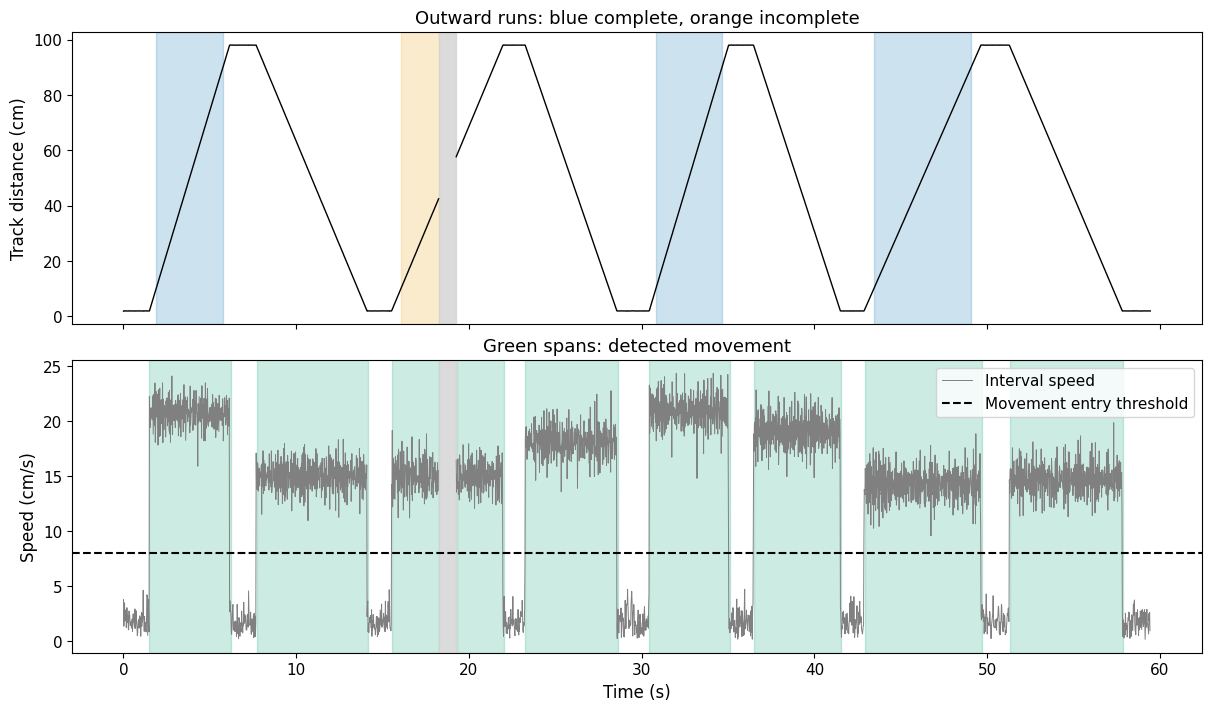

In [4]:
entries = detect_region_crossings(
    position_bins, times, track, region_name="right", direction="entry", max_gap=0.1
)
runs = detect_runs_between_regions(
    position_bins,
    times,
    track,
    source="left",
    target="right",
    min_duration=0.5,
    max_duration=12.0,
    max_gap=0.1,
)
complete_runs = [run for run in runs if run.success]
print(f"Right-region entries: {len(entries)}")
print(
    f"Outward runs: {len(complete_runs)} complete; {len(runs) - len(complete_runs)} incomplete"
)
for number, run in enumerate(runs, start=1):
    status = "target observed" if run.success else "incomplete observation / timeout"
    print(f"  {number}: {run.start_time:.2f}-{run.end_time:.2f} s; {status}")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
# Separate chunks so a line never connects observations across the gap.
chunks = np.split(np.arange(len(times)), np.flatnonzero(~observed_interval) + 1)
for chunk in chunks:
    axes[0].plot(times[chunk], linear_position[chunk], color="black", lw=1)
for run in runs:
    axes[0].axvspan(
        run.start_time,
        run.end_time,
        color="#0072B2" if run.success else "#E69F00",
        alpha=0.2,
    )
axes[0].set(
    ylabel="Track distance (cm)", title="Outward runs: blue complete, orange incomplete"
)
axes[1].plot(times[:-1], speed, lw=0.7, color="gray", label="Interval speed")
for epoch in movement:
    axes[1].axvspan(epoch.start_time, epoch.end_time, color="#009E73", alpha=0.2)
axes[1].axhline(8.0, color="black", ls="--", label="Movement entry threshold")
axes[1].set(
    xlabel="Time (s)", ylabel="Speed (cm/s)", title="Green spans: detected movement"
)
axes[1].legend(loc="upper right")
for ax in axes:
    ax.axvspan(gap_center - 0.5, gap_center + 0.5, color="lightgray", alpha=0.8)
plt.show()

Region entries and complete runs count different events: an entry can be
observed after a gap even when the source-to-target journey was not observed
continuously. Keep the incomplete segment in quality-control summaries.

## 4. Compare progress within complete traversals

Graph progress measures shortest-path distance from each run's observed start,
divided by its start-to-arrival distance. On this unbranched track it follows
distance along the bend. It is bin-quantized and does not measure cumulative
distance traveled; backtracking can reduce progress. The denominator uses the
first observed target-region bin, rather than the track's physical endpoint.
Relative time permits a descriptive comparison of traversal profiles.

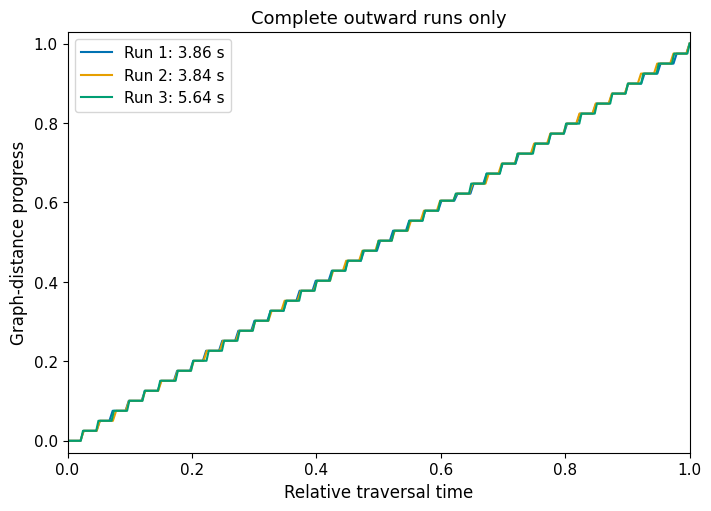

In [5]:
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
for number, run in enumerate(complete_runs, start=1):
    inside = (times >= run.start_time) & (times <= run.end_time)
    run_bins = position_bins[inside]
    run_times = times[inside]
    progress = path_progress(
        run_bins,
        track,
        start_bins=np.full(len(run_bins), run_bins[0]),
        goal_bins=np.full(len(run_bins), run_bins[-1]),
    )
    relative_time = (run_times - run_times[0]) / (run_times[-1] - run_times[0])
    ax.plot(
        relative_time,
        progress,
        label=f"Run {number}: {run_times[-1] - run_times[0]:.2f} s",
    )
ax.set(
    xlabel="Relative traversal time",
    ylabel="Graph-distance progress",
    title="Complete outward runs only",
    xlim=(0, 1),
    ylim=(-0.03, 1.03),
)
ax.legend()
plt.show()

Progress toward a chosen endpoint is not proof of goal-directed intent. This
task's track constrains the available route. In a branching maze, inspect the
chosen route and start/target pair before pooling progress curves.

The `movement` and `runs` objects expose `start_time` and `end_time`. Pass
selected intervals as `epochs=` to occupancy or rate estimation, and use the
same windows for spikes and tracking. Epoch windows are half-open `[start,
stop)`; choose endpoint conventions deliberately when counting arrival events.

Continue with [04: real-data analysis](04_real_data_analysis.ipynb), or see
the [behavior guide](https://edeno.github.io/neurospatial/user-guide/trajectory-and-behavioral-analysis/)
for trials, circular laps, turn angles, and mean-square displacement. For graph
fields and fluxes, see the
[differential-operator guide](https://edeno.github.io/neurospatial/user-guide/differential-operators/).